# Exploratory Data Analysis (EDA)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Books

In [ ]:
books = pd.read_csv("../../data/clean_books.csv")
books.head()

,name,author,rating,year,genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,2019,Childrens


In [ ]:
books.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   name    350 non-null    object 
 1   author  350 non-null    object 
 2   rating  350 non-null    float64
 3   year    350 non-null    int64  
 4   genre   350 non-null    object 
dtypes: float64(1), int64(1), object(3)
memory usage: 13.8+ KB


In [ ]:
books.value_counts("genre")

,count
genre,
Non Fiction,179
Fiction,131
Childrens,40


In [ ]:
books.describe()

,rating,year
count,350.000000,350.000000
mean,4.608571,2013.508571
std,0.226941,3.284711
min,3.300000,2009.000000
25%,4.500000,2010.000000
50%,4.600000,2013.000000
75%,4.800000,2016.000000
max,4.900000,2019.000000


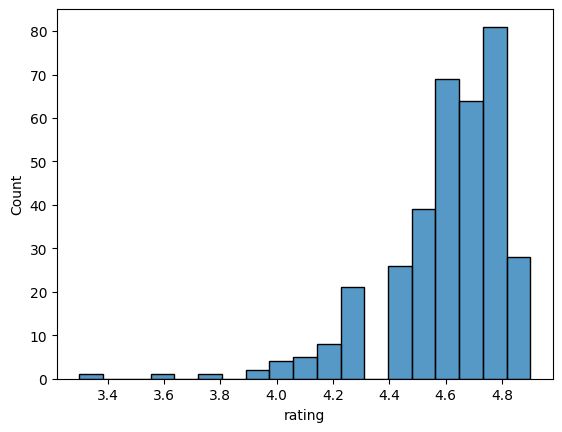

In [ ]:
sns.histplot(data=books, x="rating")
plt.show()

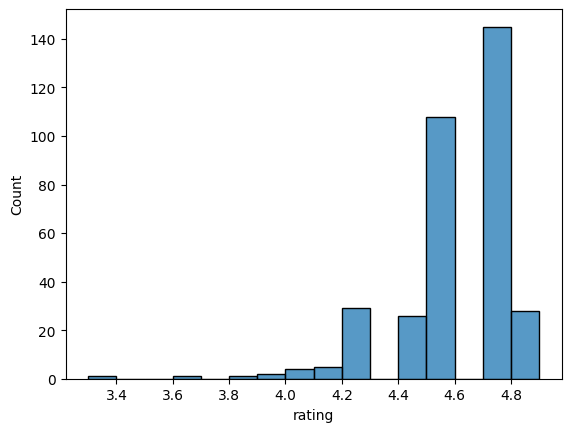

In [ ]:
sns.histplot(data=books, x="rating", binwidth=.1)
plt.show()

In [ ]:
books.dtypes

,0
name,object
author,object
rating,float64
year,int64
genre,object


In [ ]:
books["year"] = books["year"].astype(int)
books.dtypes

,0
name,object
author,object
rating,float64
year,int64
genre,object


In [ ]:
books["genre"].isin(["Fiction", "Non Fiction"])

,genre
0,True
1,True
2,True
3,True
4,False
...,...
345,True
346,True
347,True
348,True


In [ ]:
~books["genre"].isin(["Fiction", "Non Fiction"])

,genre
0,False
1,False
2,False
3,False
4,True
...,...
345,False
346,False
347,False
348,False


In [ ]:
books[books["genre"].isin(["Fiction", "Non Fiction"])].head()

,name,author,rating,year,genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,2017,Fiction
5,A Dance with Dragons (A Song of Ice and Fire),George R. R. Martin,4.4,2011,Fiction


In [ ]:
books.select_dtypes("number").head()

,rating,year
0,4.7,2016
1,4.6,2011
2,4.7,2018
3,4.7,2017
4,4.8,2019


In [ ]:
print(books["year"].min())
print(books["year"].max())

2009
2019


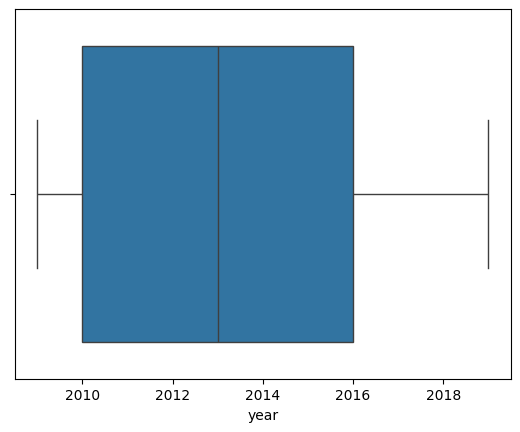

In [ ]:
sns.boxplot(data=books, x="year")
plt.show()

<Axes: xlabel='year', ylabel='genre'>

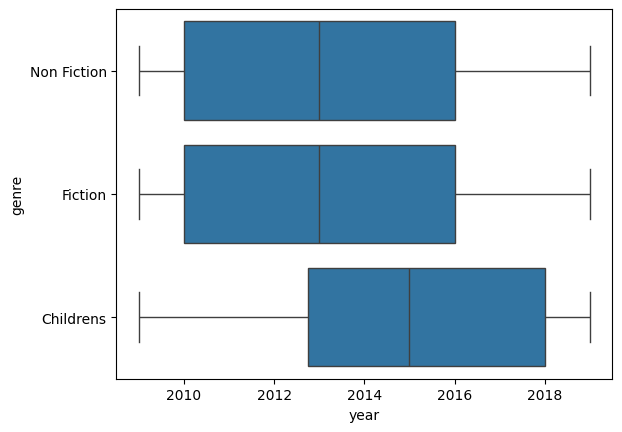

In [ ]:
sns.boxplot(data=books, x="year", y="genre")

In [ ]:
books.groupby("genre").mean(numeric_only=True)

,rating,year
genre,,
Childrens,4.780000,2015.075000
Fiction,4.570229,2013.022901
Non Fiction,4.598324,2013.513966


In [ ]:
books.select_dtypes(include='number').agg(['mean', 'std'])

,rating,year
mean,4.608571,2013.508571
std,0.226941,3.284711


In [ ]:
books.agg({"rating": ["mean", "std"], "year": ["median"]})

,rating,year
mean,4.608571,NaN
std,0.226941,NaN
median,NaN,2013.0


In [ ]:
books.groupby("genre").agg(
    mean_rating=("rating", "mean"),
    std_rating=("rating", "std"),
    median_year=("year", "median")
)

,mean_rating,std_rating,median_year
genre,,,
Childrens,4.780000,0.122370,2015.0
Fiction,4.570229,0.281123,2013.0
Non Fiction,4.598324,0.179411,2013.0


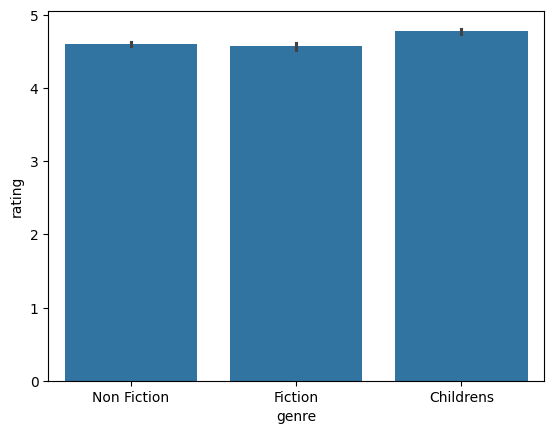

In [ ]:
sns.barplot(data=books, x="genre", y="rating")
plt.show()

## Salaries

In [ ]:
salaries = pd.read_csv("../../data/salaries_and_fields_cleaned.csv")

# Working_Year to float64
salaries['Working_Year'] = salaries['Working_Year'].astype('float64')

# Strings to string dtype
salaries['Designation'] = salaries['Designation'].astype('string')
salaries['Experience'] = salaries['Experience'].astype('string')
salaries['Employment_Status'] = salaries['Employment_Status'].astype('string')
salaries['Employee_Location'] = salaries['Employee_Location'].astype('string')
salaries['Company_Size'] = salaries['Company_Size'].astype('string')

# Remote_Working_Ratio to int64
salaries['Remote_Working_Ratio'] = salaries['Remote_Working_Ratio'].astype('int64')

# Salary_USD to float64
salaries['Salary_USD'] = salaries['Salary_USD'].astype('float64')

In [ ]:
salaries.head()

,Working_Year,Designation,Experience,Employment_Status,Employee_Location,Company_Size,Remote_Working_Ratio,Salary_USD
0,2020.0,Data Scientist,MI,FT,DE,L,0,6352272.0
1,2020.0,Principal Data Scientist,SE,FT,DE,M,100,130000.0
2,2020.0,Lead Data Engineer,SE,FT,NZ,S,50,125000.0
3,2020.0,Data Scientist,SE,FT,US,L,50,120000.0
4,2020.0,Data Scientist,MI,FT,US,M,100,118000.0


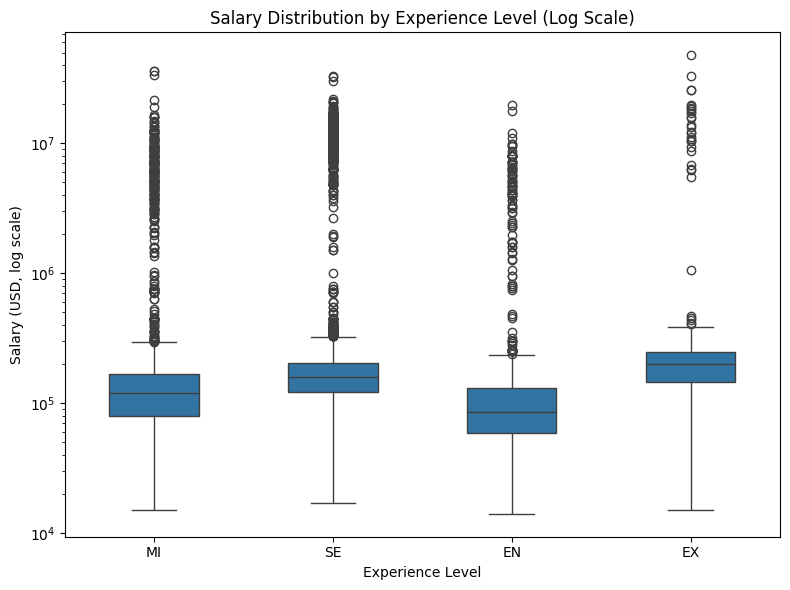

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=salaries, x="Experience", y="Salary_USD", width=0.5)
plt.yscale("log")  # log scale on y-axis
plt.title("Salary Distribution by Experience Level (Log Scale)")
plt.xlabel("Experience Level")
plt.ylabel("Salary (USD, log scale)")
plt.tight_layout()
plt.show()

In [ ]:
salaries.isna().sum()

Working_Year            0
Designation             0
Experience              0
Employment_Status       0
Employee_Location       0
Company_Size            0
Remote_Working_Ratio    0
Salary_USD              0
dtype: int64


In [ ]:

for col in salaries.columns:
    frac_missing = np.random.uniform(0.009, 0.013)
    missing_indices = salaries.sample(frac=frac_missing).index

    salaries.loc[missing_indices, col] = np.nan

In [ ]:
salaries.isna().sum()

Working_Year            162
Designation             180
Experience              172
Employment_Status       197
Employee_Location       163
Company_Size            145
Remote_Working_Ratio    176
Salary_USD              169
dtype: int64


In [ ]:
threshold = len(salaries) * 0.01
print(threshold)

154.45000000000002


In [ ]:
cols_to_drop = salaries.columns[salaries.isna().sum() <= threshold]
cols_to_drop

Index(['Company_Size'], dtype='object')

In [ ]:
salaries.dropna(subset=cols_to_drop, inplace=True)

In [ ]:
salaries.isna().sum()

,0
Working_Year,160
Designation,178
Experience,171
Employment_Status,193
Employee_Location,160
Company_Size,0
Remote_Working_Ratio,173
Salary_USD,168


In [ ]:
cols_with_missing_values = salaries.columns[salaries.isna().sum() > 0]
cols_with_missing_values

Index(['Working_Year', 'Designation', 'Experience', 'Employment_Status',
       'Employee_Location', 'Remote_Working_Ratio', 'Salary_USD'],
      dtype='object')

In [ ]:
for col	in cols_with_missing_values[:-1]:
  salaries[col] = salaries[col].fillna(salaries[col].mode()[0])

In [ ]:
salaries.isna().sum()

,0
Working_Year,0
Designation,0
Experience,0
Employment_Status,0
Employee_Location,0
Company_Size,0
Remote_Working_Ratio,0
Salary_USD,168


In [ ]:
salaries_dict = salaries.groupby("Experience")["Salary_USD"].median().to_dict()
salaries_dict

{'EN': 85128.0, 'EX': 200000.0, 'MI': 120000.0, 'SE': 156426.5}

In [ ]:
salaries["Salary_USD"] = salaries["Salary_USD"].fillna(salaries["Experience"].map(salaries_dict))

In [ ]:
salaries.isna().sum()

,0
Working_Year,0
Designation,0
Experience,0
Employment_Status,0
Employee_Location,0
Company_Size,0
Remote_Working_Ratio,0
Salary_USD,0


In [ ]:
salaries.select_dtypes("string").head()

,Designation,Experience,Employment_Status,Employee_Location,Company_Size
0,Data Scientist,MI,FT,DE,L
1,Principal Data Scientist,SE,FT,DE,M
2,Lead Data Engineer,SE,FT,US,S
3,Data Scientist,SE,FT,US,L
4,Data Scientist,MI,FT,US,M


In [ ]:
salaries["Designation"].value_counts()

,count
Designation,
Data Engineer,3399
Data Scientist,3097
Data Analyst,2242
Machine Learning Engineer,1547
Research Scientist,481
...,...
Analytics Engineering Manager,1
Quantitative Research Analyst,1
CRM Data Analyst,1


In [ ]:
salaries["Designation"].nunique()

155

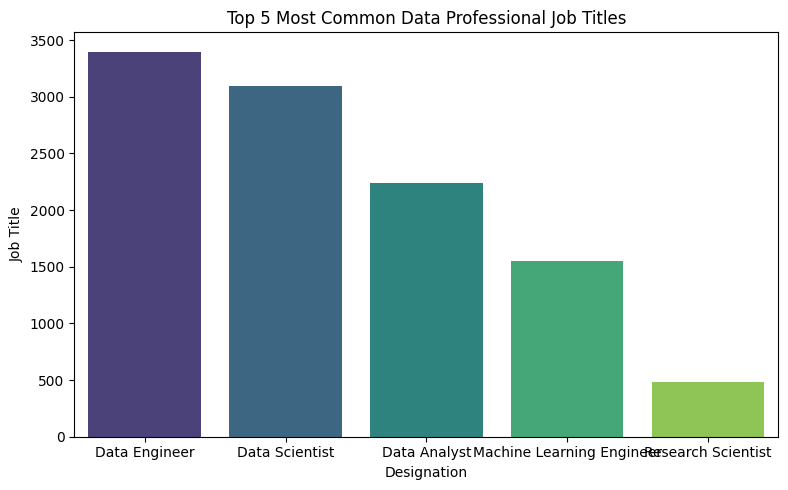

In [ ]:
# Step 1: Count occurrences of each Designation
top_5_designations = salaries['Designation'].value_counts().nlargest(5)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=top_5_designations.index,
    y=top_5_designations.values,
    hue=top_5_designations.index,
    palette='viridis',
    legend=False
)


plt.title("Top 5 Most Common Data Professional Job Titles")
plt.ylabel("Job Title")
plt.tight_layout()
plt.show()

In [ ]:
salaries["Designation"].str.contains("Scientist")

,Designation
0,True
1,True
2,False
3,True
4,True
...,...
15440,False
15441,False
15442,False
15443,False


In [ ]:
salaries["Designation"].str.contains("Machine Learning|AI")

,Designation
0,False
1,False
2,False
3,False
4,False
...,...
15440,False
15441,False
15442,False
15443,False


In [ ]:
salaries["Designation"].str.contains("^Data")

,Designation
0,True
1,False
2,False
3,True
4,True
...,...
15440,True
15441,True
15442,False
15443,True


In [ ]:
job_categories = ["Data Science", "Data Analytics", "Data Engineering", "Machine Learning", "Managerial", "Consultant"]

data_science = "Data Scientist|NLP"
data_analyst = "Analyst|Analytics"
data_engineer = "Data Engineer|ETL|Architect|Infrastructure"
ml_engineer = "Machine Learning|ML|Big Data|AI"
manager = "Manager|Head|Director|Lead|Principal|Staff"
consultant = "Consultant|Freelance"

conditions = [
    (salaries["Designation"].str.contains(data_science)),
    (salaries["Designation"].str.contains(data_analyst)),
    (salaries["Designation"].str.contains(data_engineer)),
    (salaries["Designation"].str.contains(ml_engineer)),
    (salaries["Designation"].str.contains(manager)),
    (salaries["Designation"].str.contains(consultant))
]

In [ ]:
salaries["Job_Category"] = np.select(conditions, job_categories, default="Other")

In [ ]:
salaries[["Designation", "Job_Category"]].head()

,Designation,Job_Category
0,Data Scientist,Data Science
1,Principal Data Scientist,Data Science
2,Lead Data Engineer,Data Engineering
3,Data Scientist,Data Science
4,Data Scientist,Data Science


In [ ]:
salaries.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15300 entries, 0 to 15444
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Working_Year          15300 non-null  float64
 1   Designation           15300 non-null  string 
 2   Experience            15300 non-null  string 
 3   Employment_Status     15300 non-null  string 
 4   Employee_Location     15300 non-null  string 
 5   Company_Size          15300 non-null  string 
 6   Remote_Working_Ratio  15300 non-null  float64
 7   Salary_USD            15300 non-null  float64
 8   Job_Category          15300 non-null  object 
dtypes: float64(3), object(1), string(5)
memory usage: 1.2+ MB


In [ ]:
salaries["std_dev"] = salaries.groupby("Experience")["Salary_USD"].transform(lambda x: x.std())

In [ ]:
salaries[["Experience", "std_dev"]].value_counts()

,,count
Experience,std_dev,
SE,1.949743e+06,9948
MI,1.988059e+06,3684
EN,1.564225e+06,1209
EX,4.229805e+06,459


## Planes

In [ ]:
import pandas as pd

planes = pd.read_excel("../../data/flight_price_train_cleaned.xlsx")

planes['Date_of_Journey'] = pd.to_datetime(planes['Date_of_Journey'])
planes['Dep_Time'] = pd.to_datetime(planes['Dep_Time'])
planes['Arrival_Time'] = pd.to_datetime(planes['Arrival_Time'])

planes['Duration'] = planes['Duration'].astype(float)
planes['Price'] = planes['Price'].astype(float)

In [ ]:
planes.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,2019-03-24 22:20:00,2019-03-24 01:10:00,170.0,non-stop,No info,3897.0
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,2019-05-01 05:50:00,2019-05-01 13:15:00,445.0,2 stops,No info,7662.0
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,2019-06-09 09:25:00,2019-06-09 04:25:00,1140.0,2 stops,No info,13882.0
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,2019-05-12 18:05:00,2019-05-12 23:30:00,325.0,1 stop,No info,6218.0
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,2019-03-01 16:50:00,2019-03-01 21:35:00,285.0,1 stop,No info,13302.0
